**Student Performance Predicion System**

Dataset: student_dataset.csv


1. setup

In [103]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [104]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score,classification_report, accuracy_score, recall_score, precision_score, f1_score

In [105]:
# configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
sns.set_theme(style="darkgrid")

RANDOM_STATE = 42
CSV_PATH = "C:\\Users\\nidhi\\Desktop\\Student performance predictor\\Student-performance-prediction-\\dataset\\student_dataset.csv"
TARGET_COLUMN = "exam_score"

2. Load dataset

In [106]:
df = pd.read_csv(CSV_PATH)
display(df.head())
print(f"Dataset shape: {df.shape}")

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.000,Placed
1,4,69,5,3,8,56,100.000,Placed
2,11,60,7,6,10,45,100.000,Placed
3,8,99,9,8,4,55,90.170,Placed
4,5,52,8,6,8,40,78.820,Placed


Dataset shape: (10000, 8)


3. Exploratory Data analysis(EDA)

In [107]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  str    
dtypes: float64(1), int64(6), str(1)
memory usage: 625.1 KB


In [108]:
# check for missing values
missing_values = df.isnull().sum()

No missing values 

In [109]:
# check duplicate rows
duplicate_mask = df.duplicated()
num_duplicates = duplicate_mask.sum()
print("number of duplicate rows:", num_duplicates)


number of duplicate rows: 0


There is no duplicate rows 

In [110]:
# taget distribution
print(df[TARGET_COLUMN].value_counts())
print("-"*50)
print(df[TARGET_COLUMN].value_counts(normalize=True) * 100)

exam_score
100.000    3520
88.560       10
91.000        7
82.450        7
81.970        7
           ... 
93.790        1
69.620        1
86.470        1
69.310        1
95.940        1
Name: count, Length: 3563, dtype: int64
--------------------------------------------------
exam_score
100.000   35.200
88.560     0.100
91.000     0.070
82.450     0.070
81.970     0.070
           ...  
93.790     0.010
69.620     0.010
86.470     0.010
69.310     0.010
95.940     0.010
Name: proportion, Length: 3563, dtype: float64


In [111]:
df.describe()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
count,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000,10000.000
mean,5.990,69.885,6.498,6.063,9.988,64.911,86.704
std,3.164,17.617,1.709,3.138,6.034,17.503,15.058
min,1.000,40.000,4.000,1.000,0.000,35.000,26.670
25%,3.000,55.000,5.000,3.000,5.000,50.000,76.728
50%,6.000,70.000,6.500,6.000,10.000,65.000,92.120
75%,9.000,85.000,8.000,9.000,15.000,80.000,100.000
max,11.000,100.000,9.000,11.000,20.000,95.000,100.000


Data Visulization

In [112]:
df.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.000,Placed
1,4,69,5,3,8,56,100.000,Placed
2,11,60,7,6,10,45,100.000,Placed
3,8,99,9,8,4,55,90.170,Placed
4,5,52,8,6,8,40,78.820,Placed


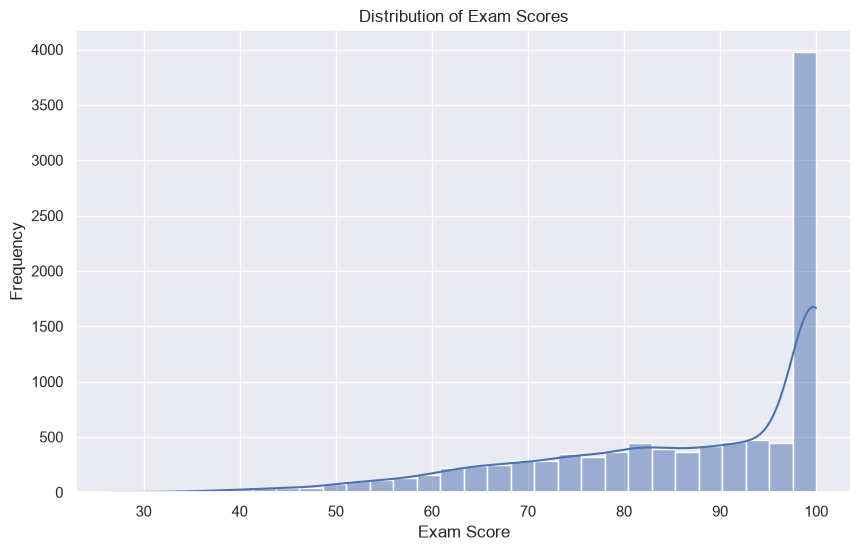

In [113]:
# target distribution plot
plt.figure(figsize=(10, 6))
sns.histplot(df[TARGET_COLUMN], bins=30, kde=True)
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")
plt.show()

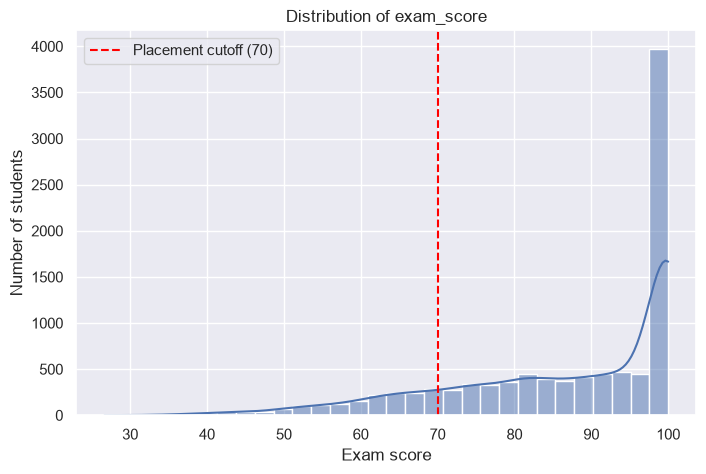

In [114]:
plt.figure(figsize=(8, 5))
sns.histplot(df["exam_score"], bins=30, kde=True)
plt.axvline(70, color="red", linestyle="--", label="Placement cutoff (70)")
plt.title("Distribution of exam_score")
plt.xlabel("Exam score")
plt.ylabel("Number of students")
plt.legend()
plt.show()

Exam scores are strongly left-skewed. About 35% of students score exactly 100, so the target is capped. Fewer students score below 70, and those who do fall in the “Not Placed” group. Because of the cap, predictions will be clipped to the 0-100 range, and the model has less information to separate students at the top.

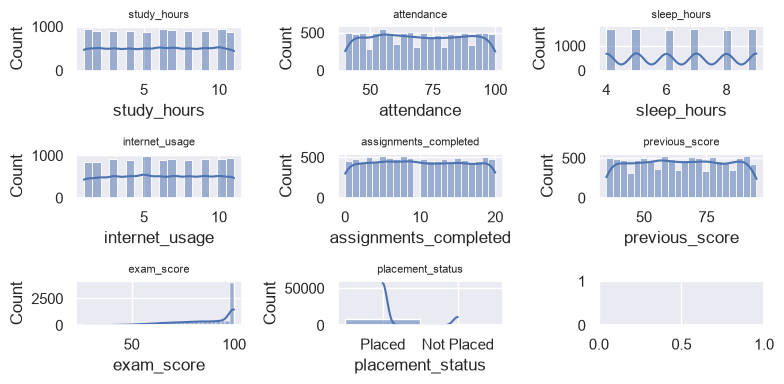

In [115]:
# histogram plot - distribution
fig, axes = plt.subplots(3, 3, figsize=(8, 4))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=8)

plt.tight_layout()
plt.show() 

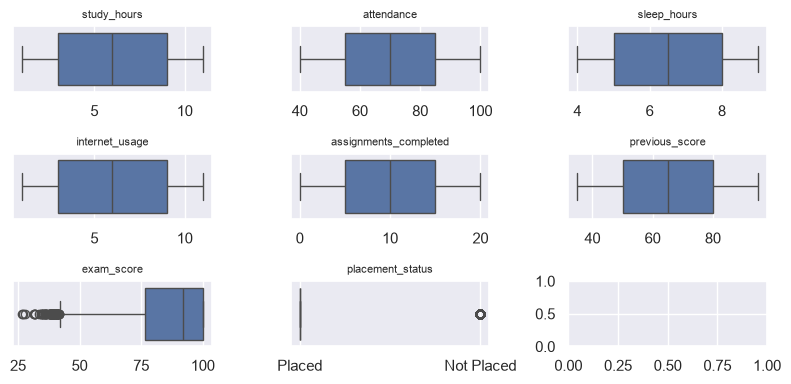

In [116]:
# outliers analysis - boxplot
fig, axes = plt.subplots(3, 3, figsize=(8, 4))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(col, fontsize=8)
    axes[i].set_xlabel("")

plt.tight_layout()
plt.show()

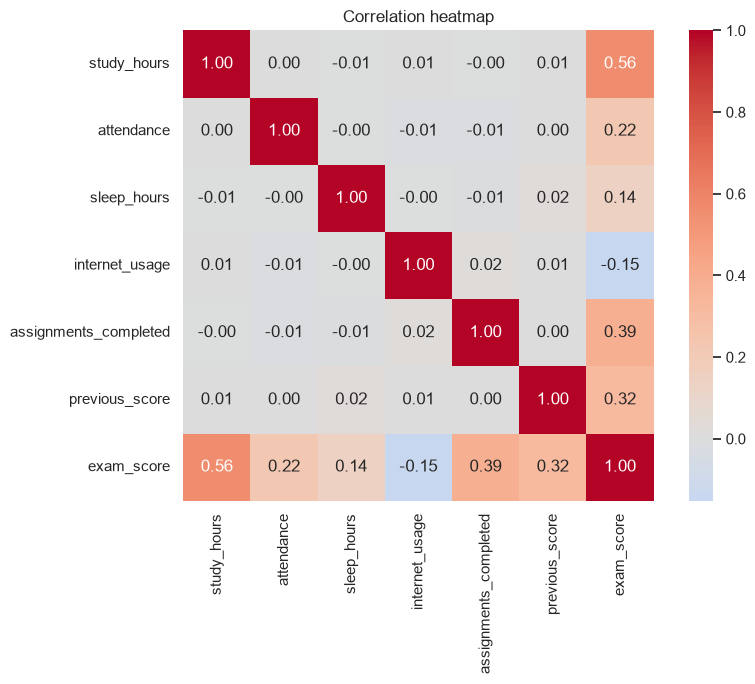

study_hours              0.563
assignments_completed    0.388
previous_score           0.319
attendance               0.223
sleep_hours              0.145
internet_usage          -0.152
Name: exam_score, dtype: float64


In [117]:
features = [c for c in df.select_dtypes(include="number").columns]
corr = df[features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

print(corr[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(ascending=False))

study_hours shows the strongest correlation with exam_score (0.56), followed by assignments_completed (0.39) and previous_score (0.32). internet_usage is weakly negative (-0.15). The features are almost uncorrelated with each other, so multicollinearity is not a concern, though this pattern suggests the dataset is synthetic.

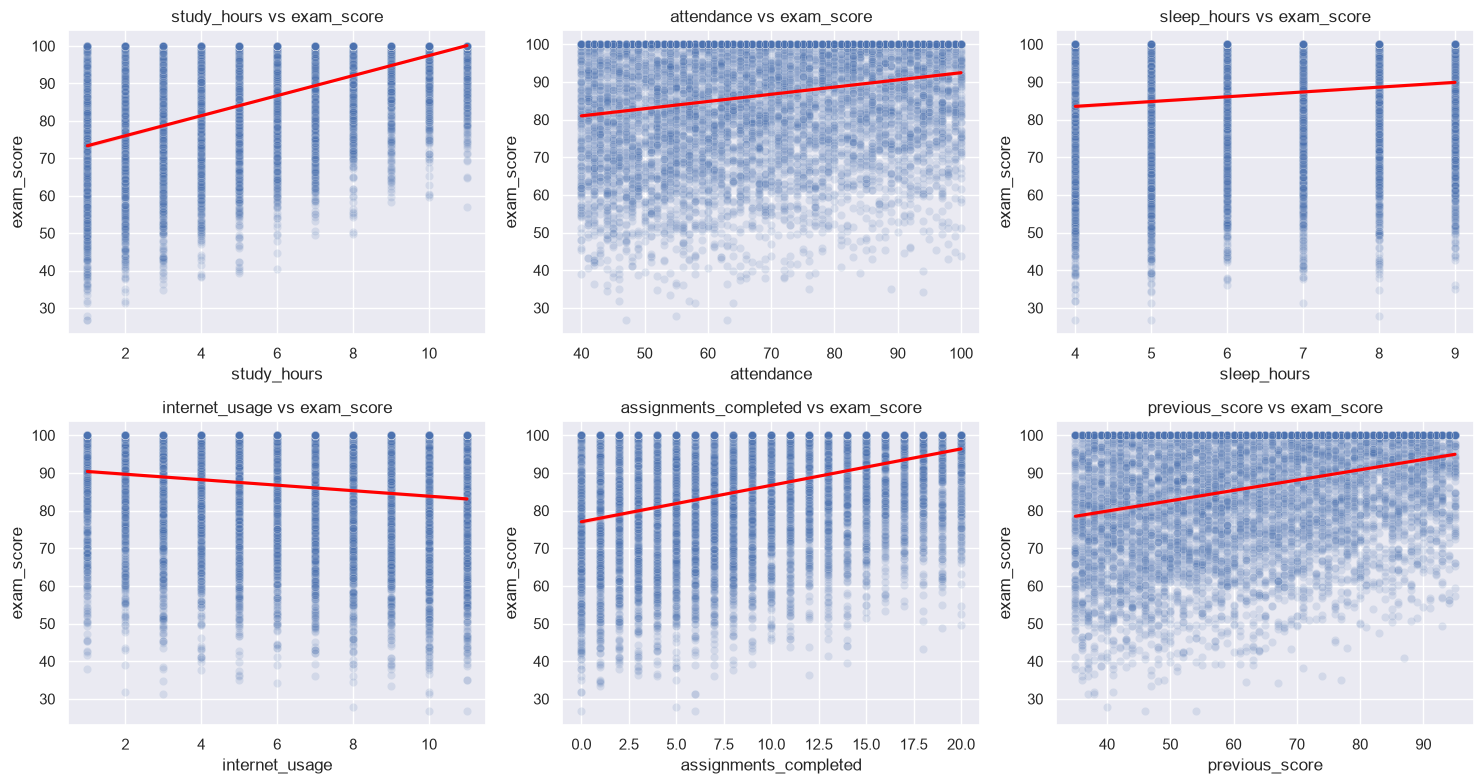

In [118]:
# Each feature against the score
feature_cols = [c for c in features if c != TARGET_COLUMN]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), feature_cols):
    sns.scatterplot(data=df, x=col, y=TARGET_COLUMN, alpha=0.15, ax=ax)
    sns.regplot(data=df, x=col, y=TARGET_COLUMN, scatter=False, color="red", ax=ax)
    ax.set_title(f"{col} vs {TARGET_COLUMN}")

plt.tight_layout()
plt.show()

study_hours has the steepest positive trend with exam_score, followed by assignments_completed and previous_score. internet_usage is the only negative relationship. Scores vary widely at every feature value, so no single feature is a strong predictor on its own. Many students are capped at 100, which flattens the trends at the top.

4. Data pre-processing

In [119]:
# separate features and target
X = df.drop(columns=[TARGET_COLUMN, "placement_status"])
y = df[TARGET_COLUMN]


In [120]:
print("Features:", list(X.columns))
print("X shape:", X.shape, "| y shape:", y.shape)


Features: ['study_hours', 'attendance', 'sleep_hours', 'internet_usage', 'assignments_completed', 'previous_score', 'placement_status']
X shape: (10000, 7) | y shape: (10000,)


In [121]:
# train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

In [122]:
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")
print(f"Share of scores at 100, train: {(y_train == 100).mean():.1%} | test: {(y_test == 100).mean():.1%}")

Train: 8000 rows | Test: 2000 rows
Share of scores at 100, train: 35.6% | test: 33.7%


In [123]:
print("Dataset size", X.shape)
print("Train Dataset size", X_train.shape)
print("Test Dataset size", X_test.shape)

Dataset size (10000, 7)
Train Dataset size (8000, 7)
Test Dataset size (2000, 7)


Pre-preocessing pipelines

In [124]:
def make_pipeline(model, scale=False):
    steps = []
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps)


def evaluate(pipe, X_tr, X_te, y_tr, y_te):
    pipe.fit(X_tr, y_tr)
    pred = np.clip(pipe.predict(X_te), 0, 100)       # scores can't exceed 100
    return {
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
        "R2": r2_score(y_te, pred),
    }

In [125]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
print(numeric_features)        # should list the six features, no placement_status

preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
    ]
)

['study_hours', 'attendance', 'sleep_hours', 'internet_usage', 'assignments_completed', 'previous_score']


In [126]:
# baseline model with preprocessing
baseline_lr = Pipeline(
    steps=[
        ("preprocess", preprocess),
        ("model", LinearRegression())
    ]
)

In [127]:
# training the pipeline
baseline_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['study_hours','attendance','sleep_hours',...,'assignments_completed', 'previous_score','placement_status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This

In [128]:
pred_lr = np.clip(baseline_lr.predict(X_test), 0, 100)

print("MAE :", mean_absolute_error(y_test, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("R2  :", r2_score(y_test, pred_lr))

MAE : 6.067339971423136
RMSE: 8.287715558651263
R2  : 0.7010251065000929


In [133]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

def build(model, scale=False):
    scaler = StandardScaler() if scale else "passthrough"
    prep = ColumnTransformer([("num", scaler, numeric_features)])
    return Pipeline([("preprocess", prep), ("model", model)])

models = {
    "Linear Regression": build(LinearRegression(), scale=True),
    "Random Forest": build(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": build(GradientBoostingRegressor(random_state=RANDOM_STATE)),
}

rows = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    pred = np.clip(pipe.predict(X_test), 0, 100)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
results

,Model,MAE,RMSE,R2
0,Gradient Boosting,5.739,7.908,0.728
1,Random Forest,5.866,8.111,0.714
2,Linear Regression,6.067,8.288,0.701


In [136]:
from sklearn.model_selection import GridSearchCV

gb_pipe = build(GradientBoostingRegressor(random_state=RANDOM_STATE))

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.8, 1.0],
}

grid = GridSearchCV(
    gb_pipe, param_grid, cv=5,
    scoring="neg_mean_absolute_error", n_jobs=-1, verbose=1,
)
grid.fit(X_train, y_train)

print("Best params :", grid.best_params_)
print("Best CV MAE :", round(-grid.best_score_, 3))
best_gb = grid.best_estimator_

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best params : {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 300, 'model__subsample': 0.8}
Best CV MAE : 5.802


Retrained with best params

In [137]:
param_grid_2 = {
    "model__n_estimators": [300, 500, 800],
    "model__learning_rate": [0.02, 0.05],
    "model__max_depth": [4, 5],
    "model__subsample": [0.7, 0.8],
}

grid2 = GridSearchCV(gb_pipe, param_grid_2, cv=5,
                     scoring="neg_mean_absolute_error", n_jobs=-1, verbose=1)
grid2.fit(X_train, y_train)

print("Best params :", grid2.best_params_)
print("Best CV MAE :", round(-grid2.best_score_, 3))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best params : {'model__learning_rate': 0.02, 'model__max_depth': 5, 'model__n_estimators': 500, 'model__subsample': 0.8}
Best CV MAE : 5.779


In [138]:
def score(pipe, name):
    pred = np.clip(pipe.predict(X_test), 0, 100)
    return {"Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "R2": r2_score(y_test, pred)}

final_table = pd.DataFrame([
    score(models["Linear Regression"], "Linear Regression (baseline)"),
    score(models["Gradient Boosting"], "Gradient Boosting (default)"),
    score(best_gb, "Gradient Boosting (tuned)"),
]).round(3)
final_table

,Model,MAE,RMSE,R2
0,Linear Regression (baseline),6.067,8.288,0.701
1,Gradient Boosting (default),5.739,7.908,0.728
2,Gradient Boosting (tuned),5.578,7.812,0.734


Gradient Boosting, tuned with 5-fold GridSearchCV, achieved a test MAE of 5.58 and R² of 0.73, compared with 6.07 and 0.70 for the Linear Regression baseline. Predictions are typically within about 5.6 marks of the actual exam score. Tuning gave only a small gain, and several other model families scored similarly, which suggests the six features limit performance more than the choice of algorithm.

In [139]:
from pathlib import Path

ROOT = Path("..")                                    # notebook is in notebooks/
RESULTS_PATH = ROOT / "reports" / "model_results.csv"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"

for d in (RESULTS_PATH.parent, FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(RESULTS_PATH.resolve())
print(FIG_DIR.resolve())
print(MODEL_DIR.resolve())

C:\Users\nidhi\Desktop\Student performance predictor\Student-performance-prediction-\reports\model_results.csv
C:\Users\nidhi\Desktop\Student performance predictor\Student-performance-prediction-\reports\figures
C:\Users\nidhi\Desktop\Student performance predictor\Student-performance-prediction-\models


In [140]:
print(Path.cwd())

c:\Users\nidhi\Desktop\Student performance predictor\Student-performance-prediction-\notebook_dir


In [141]:
final_table.to_csv(RESULTS_PATH, index=False)

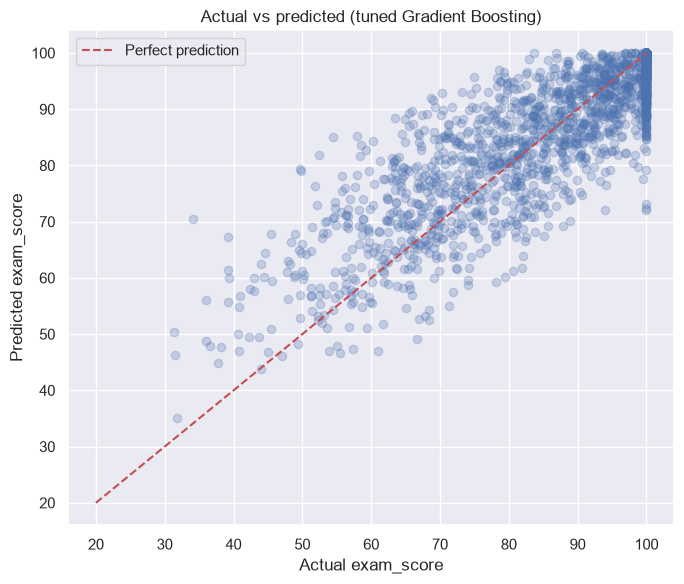

In [142]:
pred = np.clip(best_gb.predict(X_test), 0, 100)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred, alpha=0.25)
plt.plot([20, 100], [20, 100], "r--", label="Perfect prediction")
plt.xlabel("Actual exam_score")
plt.ylabel("Predicted exam_score")
plt.title("Actual vs predicted (tuned Gradient Boosting)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "05_actual_vs_predicted.png", dpi=150)
plt.show()

Predictions track actual scores but with wide spread, consistent with R² of 0.73. The model under-predicts students who scored 100 (a capped group that is hard to separate) and over-predicts the lowest scorers, a regression-to-the-mean effect. Errors are largest at both extremes of the score range.

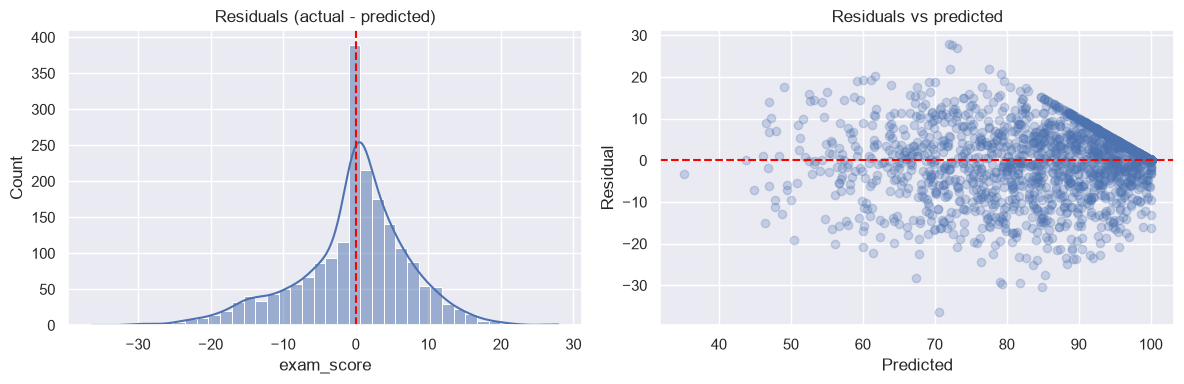

In [143]:
# errors
residuals = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(residuals, bins=40, kde=True, ax=ax[0])
ax[0].axvline(0, color="red", linestyle="--")
ax[0].set_title("Residuals (actual - predicted)")

ax[1].scatter(pred, residuals, alpha=0.25)
ax[1].axhline(0, color="red", linestyle="--")
ax[1].set_xlabel("Predicted")
ax[1].set_ylabel("Residual")
ax[1].set_title("Residuals vs predicted")

plt.tight_layout()
plt.savefig(FIG_DIR / "06_residuals.png", dpi=150)
plt.show()

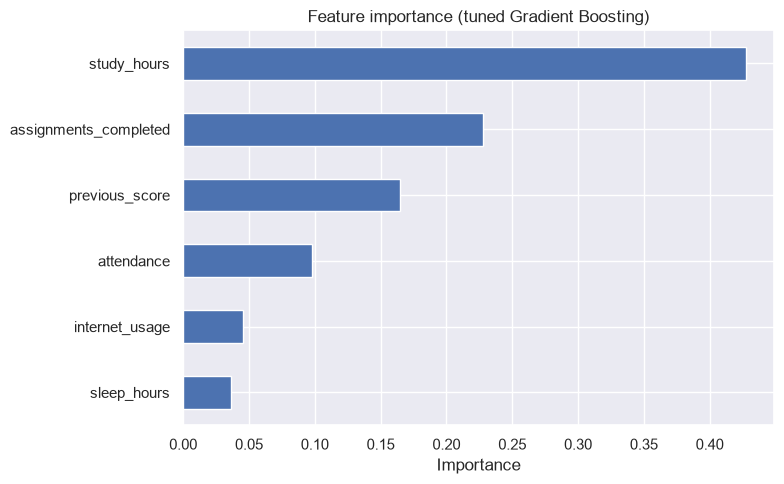

study_hours             0.427
assignments_completed   0.228
previous_score          0.165
attendance              0.098
internet_usage          0.046
sleep_hours             0.036
dtype: float64

In [144]:
importances = pd.Series(
    best_gb.named_steps["model"].feature_importances_,
    index=best_gb.named_steps["preprocess"].get_feature_names_out(),
)
importances.index = [i.replace("num__", "") for i in importances.index]
importances = importances.sort_values()

plt.figure(figsize=(8, 5))
importances.plot(kind="barh")
plt.title("Feature importance (tuned Gradient Boosting)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_feature_importance.png", dpi=150)
plt.show()

importances.sort_values(ascending=False).round(3)

In [145]:
import joblib

joblib.dump(best_gb, MODEL_DIR / "student_model.joblib")

reloaded = joblib.load(MODEL_DIR / "student_model.joblib")
print("Reload check:", np.allclose(reloaded.predict(X_test), best_gb.predict(X_test)))
print("Features expected:", list(reloaded.feature_names_in_))

Reload check: True
Features expected: ['study_hours', 'attendance', 'sleep_hours', 'internet_usage', 'assignments_completed', 'previous_score', 'placement_status']


prediction

In [151]:
# 1. features without the text column
X = df.drop(columns=["exam_score", "placement_status"])
y = df["exam_score"]
print(X.columns.tolist())            # exactly six names

# 2. same split as before (same random_state, so the same rows)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

# 3. rebuild the pipeline helper's column list, then refit with the tuned settings
numeric_features = X_train.columns.tolist()

best_gb = build(GradientBoostingRegressor(
    learning_rate=0.02, max_depth=5, n_estimators=500,
    subsample=0.8, random_state=RANDOM_STATE,
))
best_gb.fit(X_train, y_train)

# 4. check the model now expects six features
print(best_gb.feature_names_in_)
print(len(best_gb.feature_names_in_))      # 6

['study_hours', 'attendance', 'sleep_hours', 'internet_usage', 'assignments_completed', 'previous_score']
['study_hours' 'attendance' 'sleep_hours' 'internet_usage'
 'assignments_completed' 'previous_score']
6


In [152]:
pred = np.clip(best_gb.predict(X_test), 0, 100)
print("MAE :", mean_absolute_error(y_test, pred))     # should be about 5.58, as before
print("R2  :", r2_score(y_test, pred))                # about 0.734

joblib.dump(best_gb, MODEL_DIR / "student_model.joblib")

MAE : 5.590538333955627
R2  : 0.732938230721401


['..\\models\\student_model.joblib']

In [154]:
import joblib

model = joblib.load(MODEL_DIR / "student_model.joblib")
FEATURES = list(model.feature_names_in_)
print(FEATURES)                       # should list six names

def predict_score(study_hours, attendance, sleep_hours,
                  internet_usage, assignments_completed, previous_score):
    row = pd.DataFrame([[study_hours, attendance, sleep_hours,
                         internet_usage, assignments_completed, previous_score]],
                       columns=FEATURES)
    score = float(np.clip(model.predict(row)[0], 0, 100))
    return round(score, 1)

score = predict_score(study_hours=9, attendance=90, sleep_hours=7,
                      internet_usage=3, assignments_completed=18, previous_score=75)

print("Predicted exam score:", score)
print("Result:", "Likely PLACED" if score >= 70 else "AT RISK")

['study_hours', 'attendance', 'sleep_hours', 'internet_usage', 'assignments_completed', 'previous_score']
Predicted exam score: 100.0
Result: Likely PLACED
